In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact

import sys
sys.path.append('../src')

from em_clustering import (
    recursive_em_split, 
    reassign_cells
)

from visualization import (
    plot_cost_function_with_minima, 
    plot_ploidy_optimization,
    plot_ploidy_comparison,  
    plot_overlap_matrix_figure,
    plot_uniformity_histograms_nice
)
from copy_number import (
    make_unif_dict,
    compute_read_counts_relative_to_normal, 
    compute_average_segment_counts, 
    compute_optimal_ploidy_and_profile,
    create_copy_number_matrix_fast
)

import time

/home/ranade/miniconda3/lib/python3.6/site-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


In [2]:
# 1. Load Data
tumor ="t46"
infilename = f"../data/{tumor}/{tumor}.bin_count_table_all_cells.txt"
bincounts = pd.read_csv(infilename, sep="\t")
bincounts_no_WGS = pd.read_csv(f"../data/{tumor}/{tumor}.bincounts_without_WGS_segmentation.txt", sep="\t")

In [3]:
bincounts.head()

,chrom,loc.start,loc.end,abstart,abend,AAAACCAAACTTAGAGA,AAAACCAAAGTAGTTCT,AAAACCAAATCCCGTCT,AAAACCAACAAGACAAT,AAAACCAACAAGATTGG,...,TTGGACGTTTTACGAAT,TTGGGATAAACCATACG,TTTCGAGTTTTACAATA,TTTCGATGGTGCGAATC,TTTCGATTCGGCCGTTC,TTTTGGAGAATTTAAGC,TTTTGGATGAGGGTAGC,TTTTGGGTTTTACTAGA,TTTTGGTGCAGGACTTC,TTTTGGTTTAGTAGACT
0,chr1,0,112738004,0,112738004,6345,1901,1276,3337,523,...,1833,856,2350,3997,79,807,645,99,3835,1220
1,chr1,113307844,120035598,113307844,120035598,523,143,97,224,25,...,51,33,386,461,63,197,53,4,359,124
2,chr1,120811216,144545019,120811216,144545019,258,113,106,148,17,...,94,25,212,191,81,145,42,26,140,60
3,chr1,145591762,198579918,145591762,198579918,2916,929,902,1590,241,...,640,481,3164,3303,190,1313,423,107,3987,1163
4,chr1,199117203,248389233,199117203,248389233,2602,889,704,1479,394,...,531,469,3114,3066,69,946,500,307,3525,919


In [4]:
bincounts_no_WGS.head()

,chrom,abstart,abend,AAAACCAAACTTAGAGA,AAAACCAAACTTTATTC,AAAACCAAAGTAGTTCT,AAAACCAAATCCCGTCT,AAAACCAACAAGACAAT,AAAACCAACAAGATTGG,AAAACCAACCGAGTAGC,...,TTTTGGGTTCCCCTATC,TTTTGGGTTTTACTAGA,TTTTGGTACCGTACAGC,TTTTGGTGAACATTACC,TTTTGGTGATGATCATC,TTTTGGTGCAGGACTTC,TTTTGGTTAAGGGTATG,TTTTGGTTAAGGGTTCT,TTTTGGTTTAGTAGACT,lengths
0,chr1,10001,32635947,2328,998,563,356,1250,141,143,...,230,60,1736,429,2496,885,248,593,380,32625946
1,chr1,32635964,64627934,2379,1444,571,510,1245,158,211,...,226,26,1322,455,2468,1254,227,768,372,31991970
2,chr1,64627934,96543520,2505,2272,694,427,1230,195,431,...,267,36,1028,523,2148,1633,213,1430,387,31915586
3,chr1,96543554,144326980,2377,2027,642,391,1185,115,220,...,270,41,1271,421,2332,1544,276,1365,409,47783426
4,chr1,144326980,169873873,1988,2017,480,532,1040,164,219,...,332,26,1522,377,2873,2464,277,905,595,25546893


In [5]:
# Use ALL cells instead of filtered cells
all_cell_names = [col for col in bincounts.columns if col not in ['chrom', 'abstart', 'abend', 'lengths','loc.start','loc.end']]
cells = pd.read_csv(f"../data/{tumor}/{tumor}.not_broken_final_list.txt", header=None)[0].values


In [6]:
# Prepare data
data = bincounts[["chrom", "abstart", "abend"] + all_cell_names].copy()
data["lengths"] = data["abend"] - data["abstart"]
all_data = data[cells].copy()
data_no_WGS = bincounts_no_WGS[["chrom", "abstart", "abend"] + all_cell_names].copy()
data_no_WGS["lengths"] = data_no_WGS["abend"] - data_no_WGS["abstart"]
all_data_no_WGS = data_no_WGS[cells].copy()


In [7]:
all_data.head()

,AAAACCAAACTTAGAGA,AAAACCAAAGTAGTTCT,AAAACCAACAAGACAAT,AAAACCAACTTTCGACA,AAAACCCTGTTTGATTA,AAAACCGAGGTAACAAT,AAAACCGAGGTATGTGG,AAAACCGGTGACTCTAC,AAAACCGTGCAAAATTG,AAAACCGTTCCCAATTG,...,TTGGGATGTTAACTTGT,TTTCGATGATGACGTGA,TTTCGATGGCGACATCC,TTTTGGAAATCCATTGG,TTTTGGAGAGCGGGTAT,TTTTGGCTTGGCCATAA,TTTTGGGCCTCTATTCC,TTTTGGGTCTTTGCATA,TTTTGGGTTCCCCGATG,TTTTGGGTTCCCCTATC
0,6345,1901,3337,2160,1637,1996,1103,1683,1523,1615,...,6388,4165,1767,3057,4965,2815,2394,2660,4666,738
1,523,143,224,222,119,184,102,153,176,174,...,548,279,121,255,408,169,189,190,392,66
2,258,113,148,101,106,105,66,116,124,62,...,266,194,75,166,206,222,90,156,243,29
3,2916,929,1590,1142,845,1141,673,1222,2005,1160,...,5016,3353,913,1926,2520,2219,1254,2391,3381,558
4,2602,889,1479,1108,1095,999,485,1157,1584,978,...,4789,3440,793,1728,2190,969,1270,1807,3116,504


Running recursive EM split A...
Processing population A with 1368 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Slopes for A: max=3.949, min=0.404
Split accepted for A: 264 + 1104 cells
  Processing population A1 with 264 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
  Slopes for A1: max=1.714, min=0.751
  Split produces too small subpopulations for A1
  Processing population A2 with 1104 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
  Slopes for A2: max=1.747, min=0.816
  Split accepted for A2: 583 + 521 cells
    Processing population A21 with 583 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new see

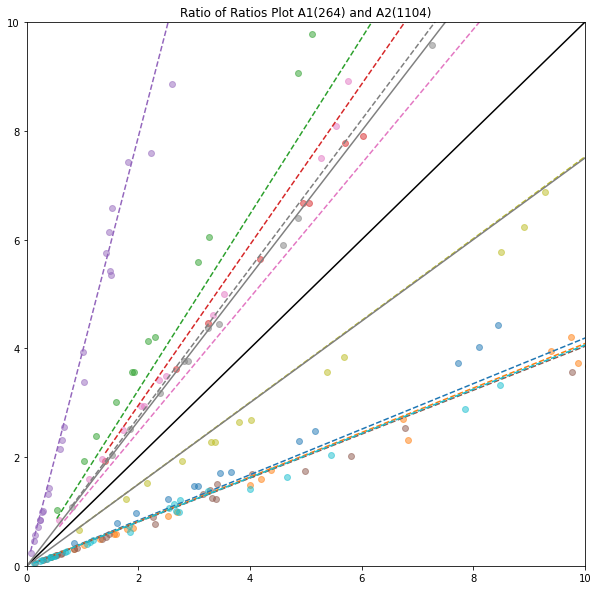

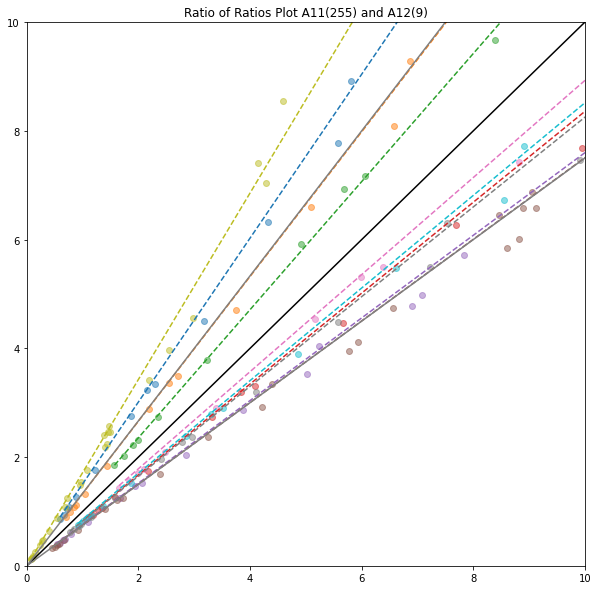

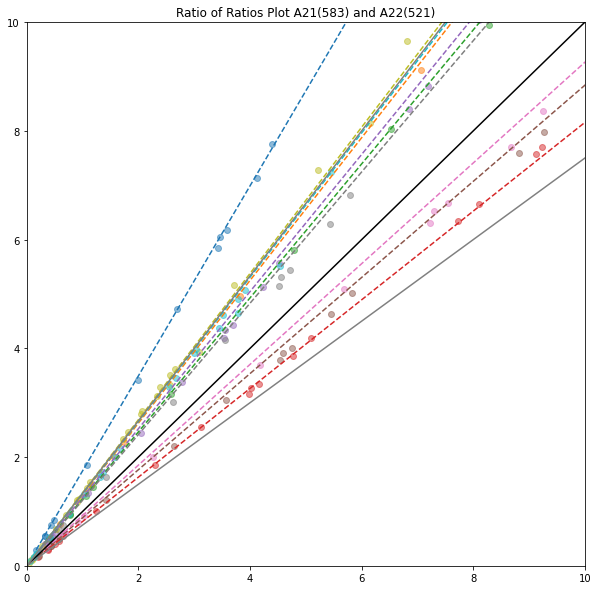

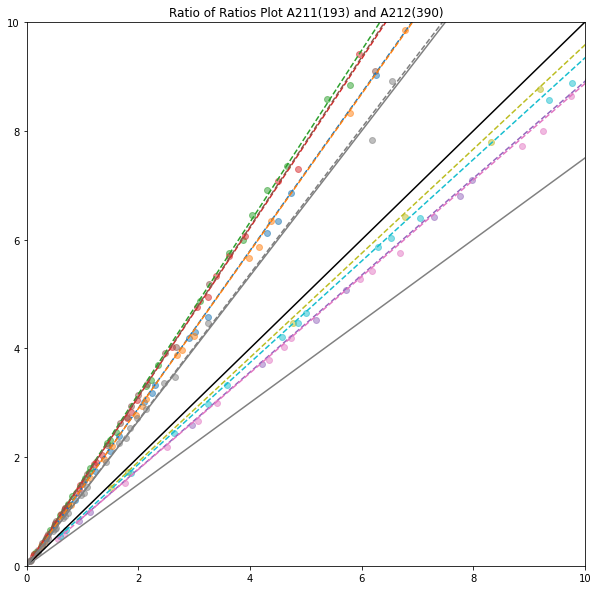

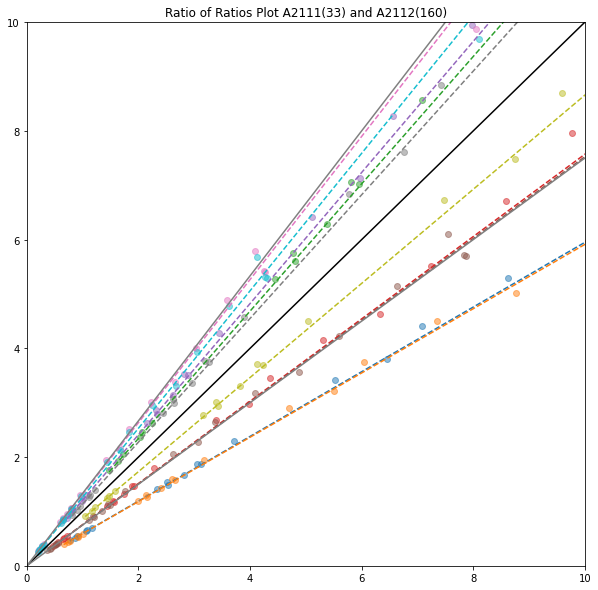

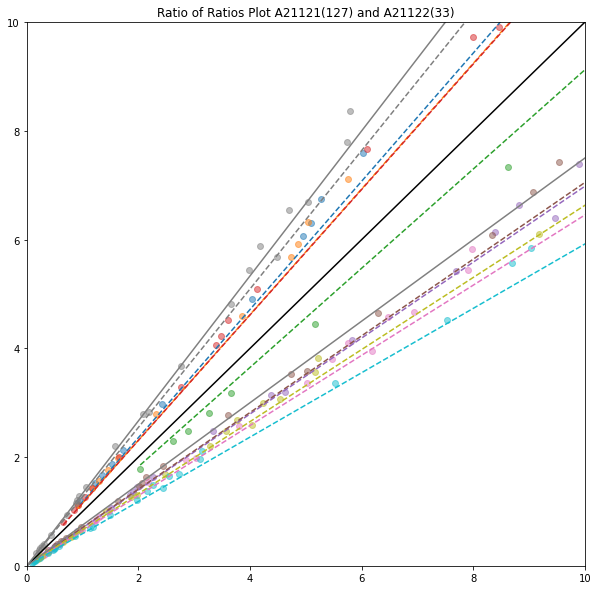

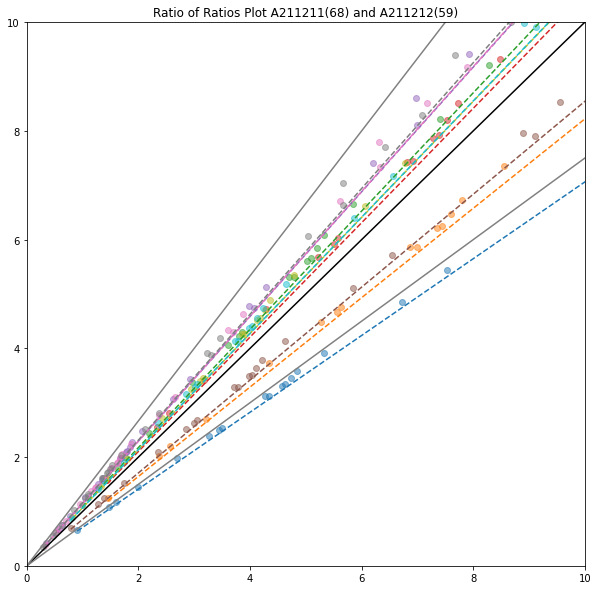

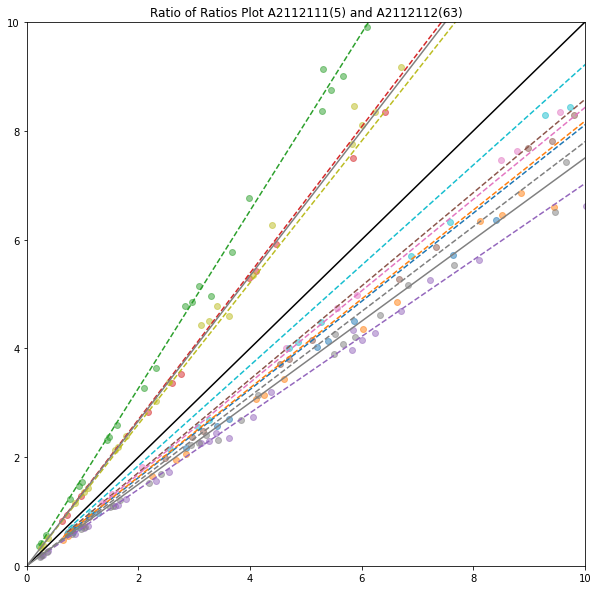

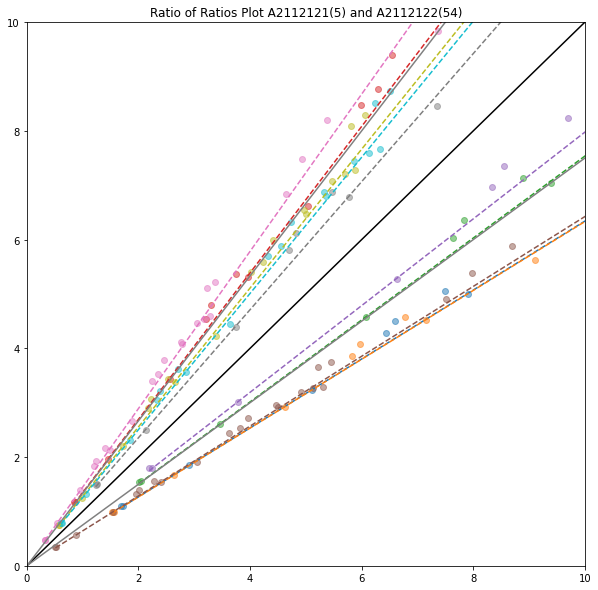

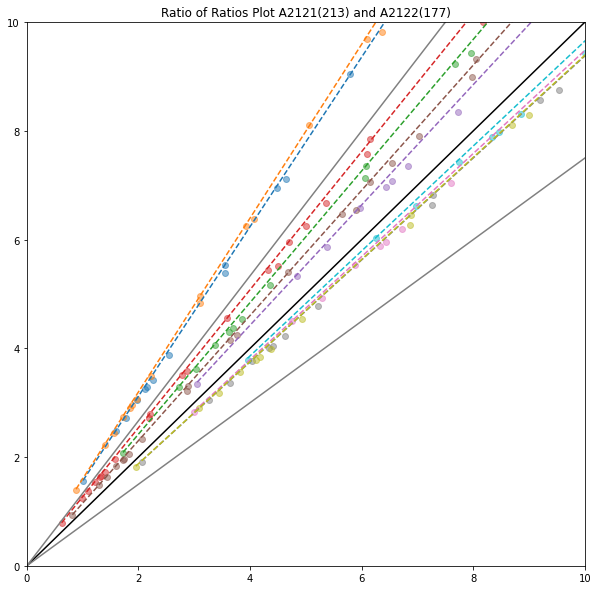

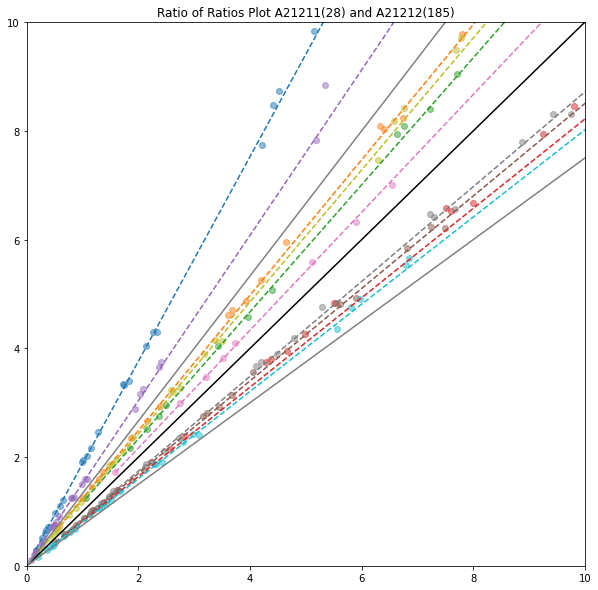

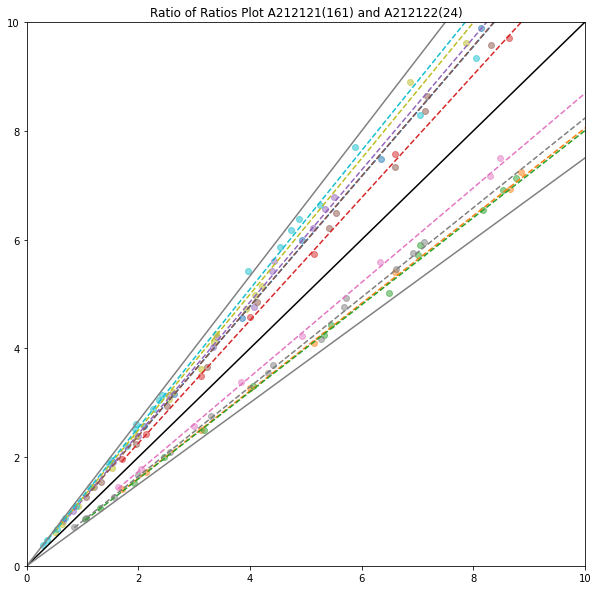

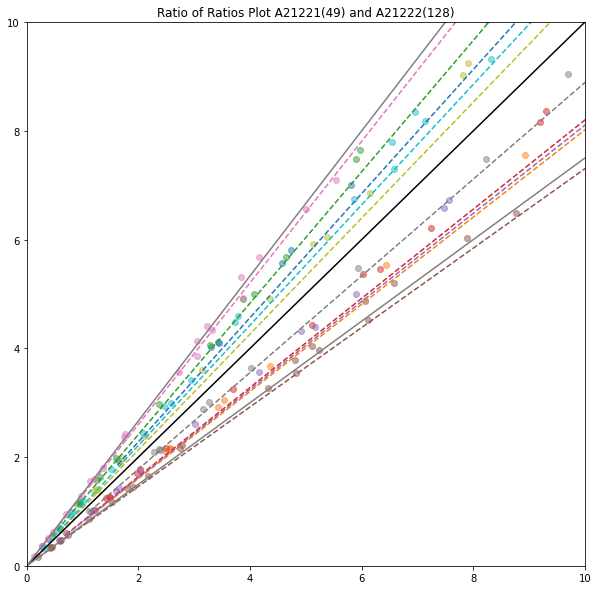

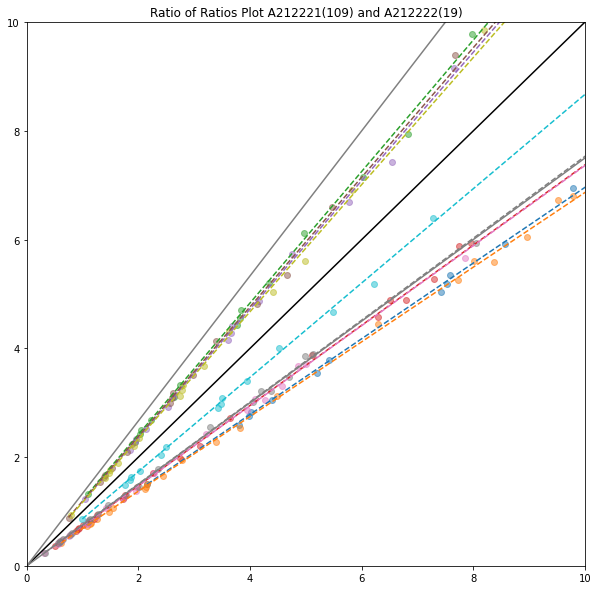

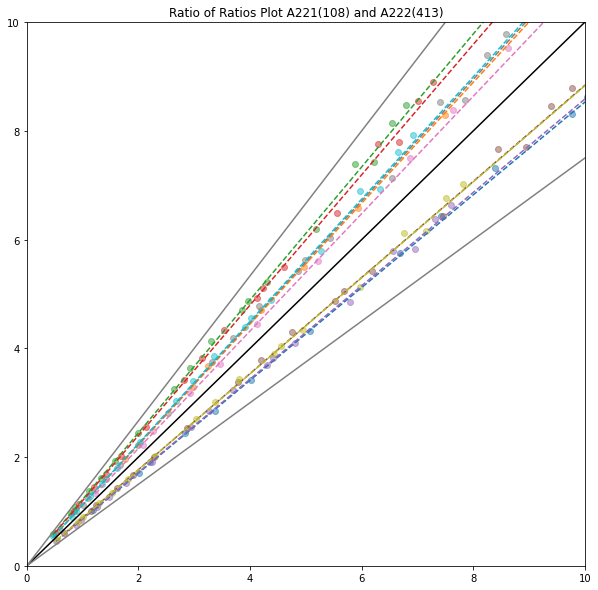

In [8]:
# 2. Run Recursive EM Splitting (two independent runs)
print("Running recursive EM split A...")
final_populations_A = recursive_em_split(
    all_data, cells, 
    threshold=3/4, max_depth=10, name="A"
)

Processing population B with 1368 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Slopes for B: max=2.308, min=0.490
Split accepted for B: 263 + 1105 cells
  Processing population B1 with 263 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
  Slopes for B1: max=1.153, min=0.702
  Split accepted for B1: 237 + 26 cells
    Processing population B11 with 237 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
    Slopes for B11: max=1.285, min=0.790
    Split rejected for B11: slopes between 0.750 and 1.333
    Processing population B12 with 26 cells
    Population B12 too small to split
  Processing population B2 with 1105 cells
Trying new seed


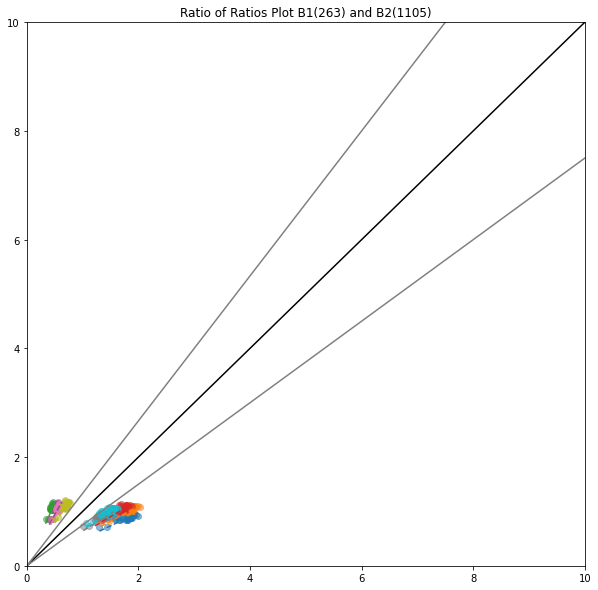

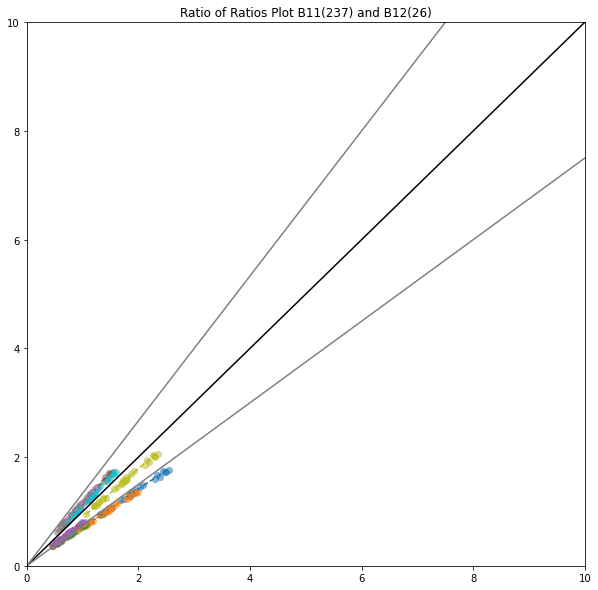

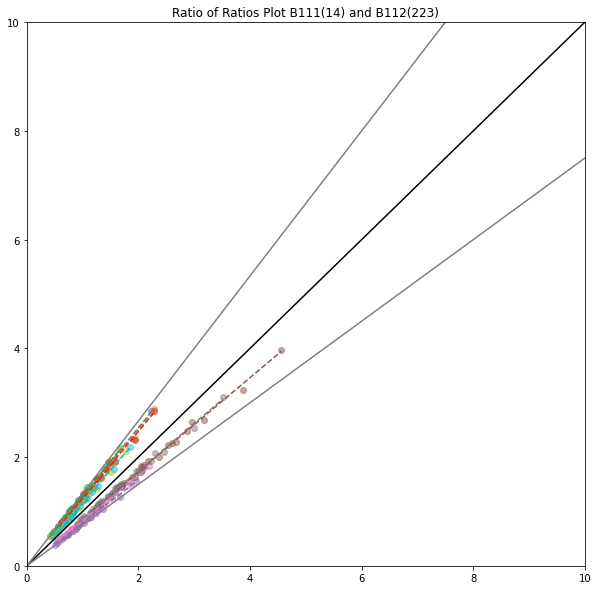

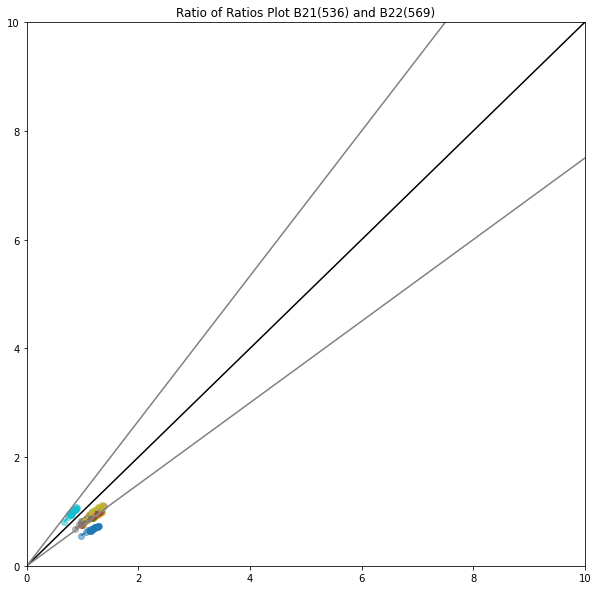

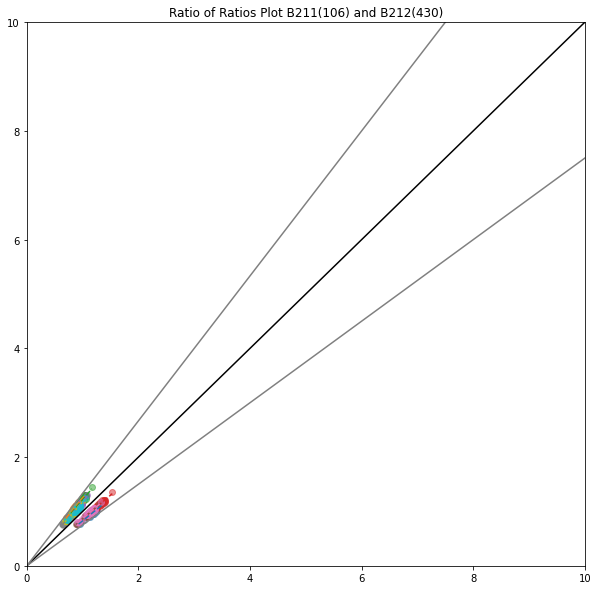

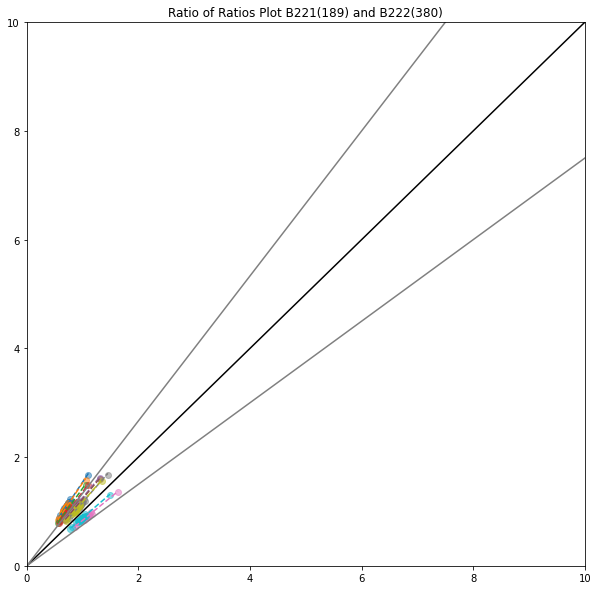

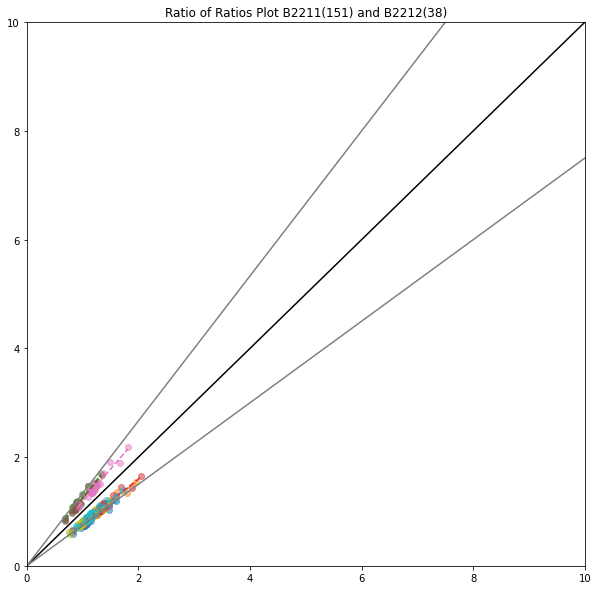

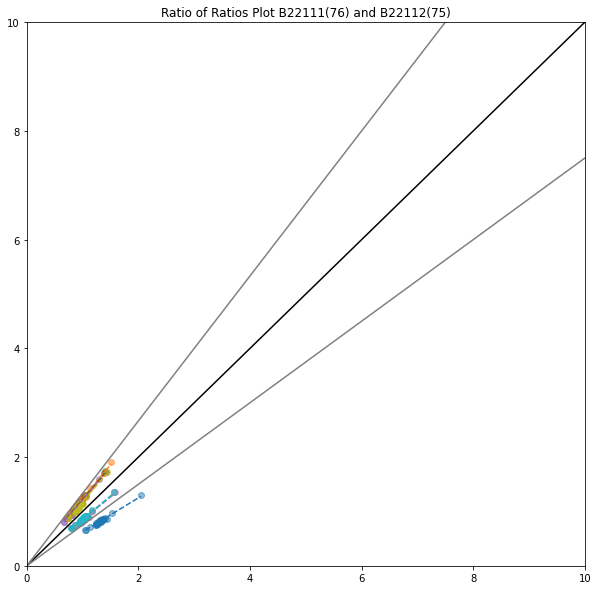

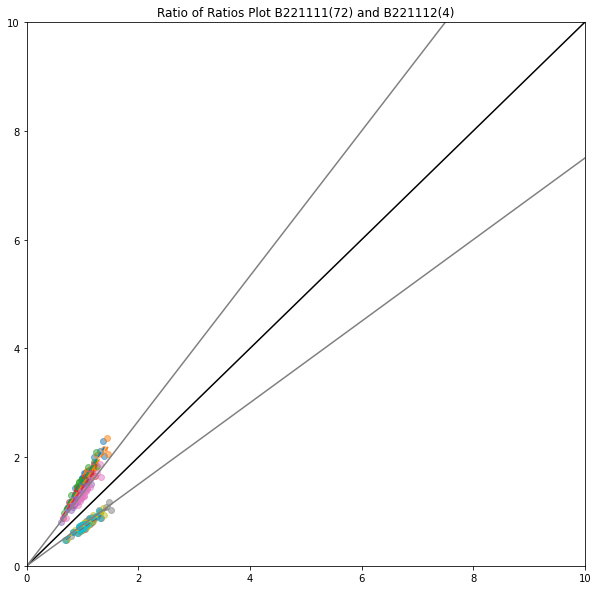

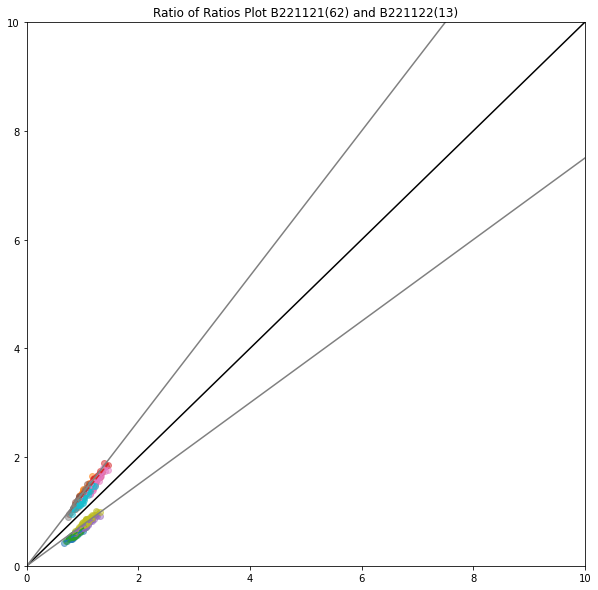

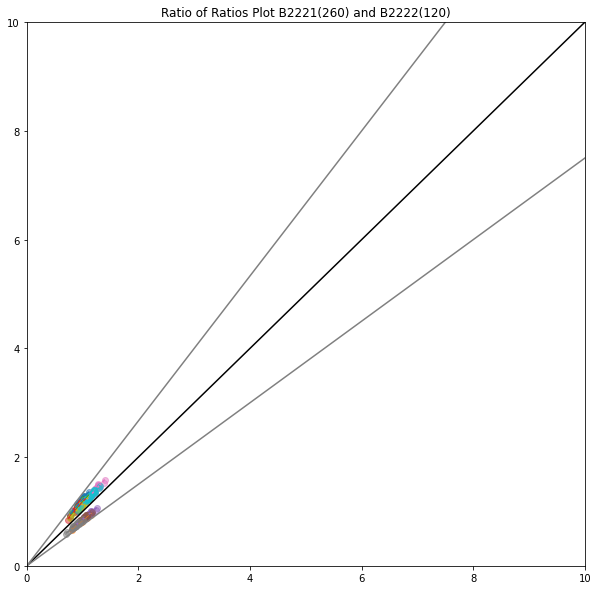

In [9]:
final_populations_B = recursive_em_split(
    all_data_no_WGS, cells, 
    threshold=3/4, max_depth=10, name="B"
)

In [10]:
# 3. Reassign cells based on multinomial parameters
A_dict = reassign_cells(all_data, final_populations_A)
B_dict = reassign_cells(all_data_no_WGS, final_populations_B)



Overlap Matrix (A rows vs B cols):
Pop          B11     B12     B21  B22111  B22112   B2212    B222
A1           236      26       0       1       0       0       0
A2111          0       0       0       7       0      18       6
A211211        0       0       2      66       5       2       1
A211212        0       0       2       5      61       4       2
A21122         0       0       1       4      18      12       0
A21211         0       0       0       1       4       1      23
A21212         0       0      13       3      19       1     153
A21221         0       0       5       1       0       0      55
A21222         0       0       5       2       2       0     128
A22            0       1     470       0       1       1       0


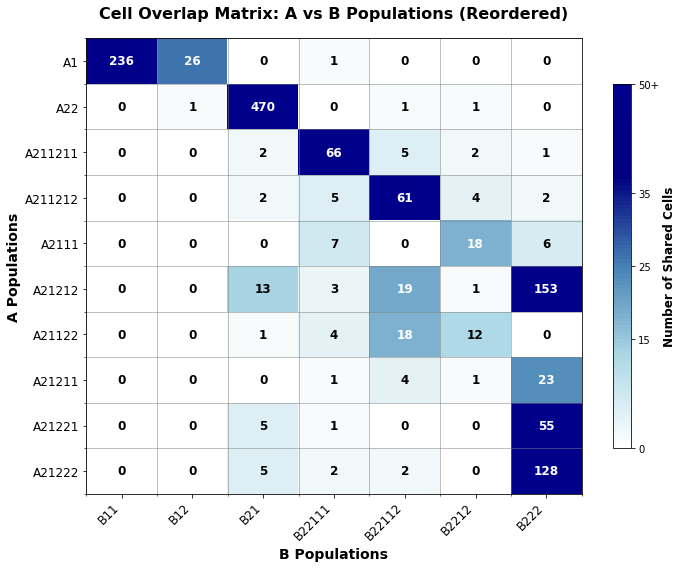

In [11]:
overlap_df = plot_overlap_matrix_figure(A_dict, B_dict)

In [ ]:
# # Save population assignments A_dict to a text file
# output_file = f"../data/{tumor}/{tumor}_population_assignments_A_WGS_bins.txt"
# with open(output_file, 'w') as f:
#     #header
#     f.write("cell\tpopulation\n")
#     for pop_name, details in A_dict.items():
#         cell_list = details['cells']
#         for cell in cell_list:
#             f.write(f"{cell}\t{pop_name}\n")

# #Save population assignments B_dict to a text file
# output_file = f"../data/{tumor}/{tumor}_population_assignments_B_equi_bins.txt"
# with open(output_file, 'w') as f:
#     #header
#     f.write("cell\tpopulation\n")
#     for pop_name, details in B_dict.items():
#         cell_list = details['cells']
#         for cell in cell_list:
#             f.write(f"{cell}\t{pop_name}\n")